<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa



Total Samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']

Training Samples: 120
Testing Samples: 30

========== KNN MODEL TRAINED ==========
Algorithm: K-Nearest Neighbours
Number of Neighbours (K): 5

========== PREDICTION RESULTS ==========


,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Testing Accuracy: 93.33 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



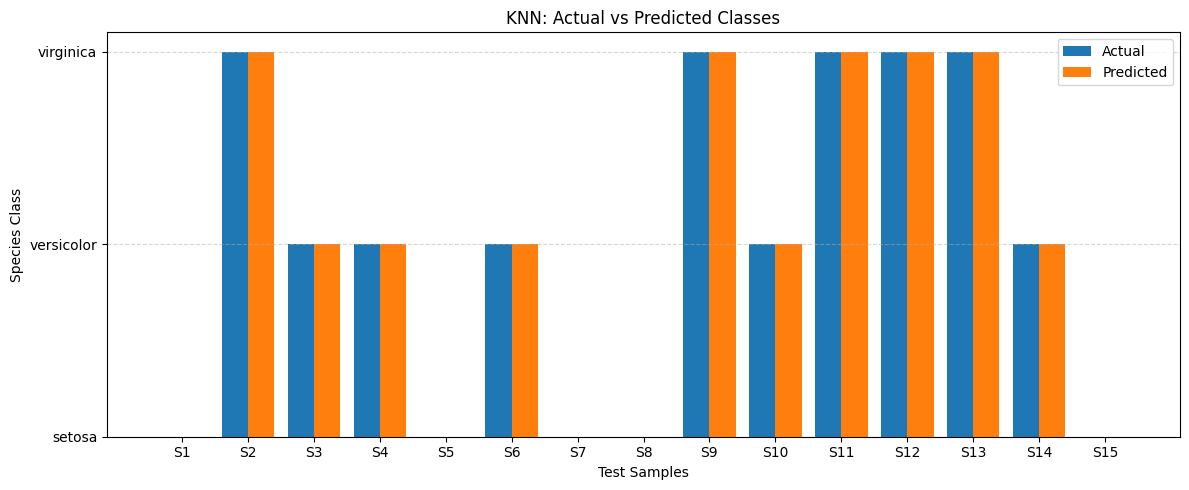

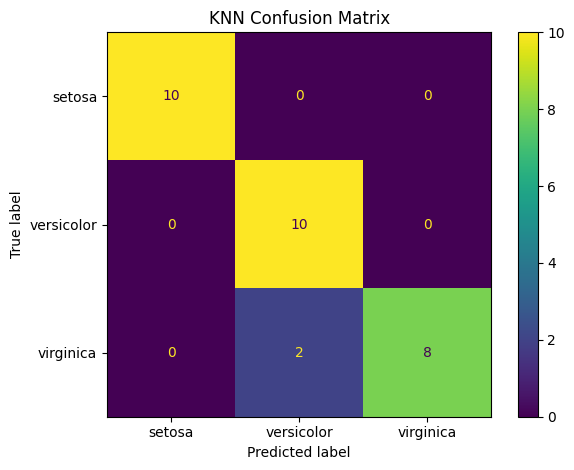

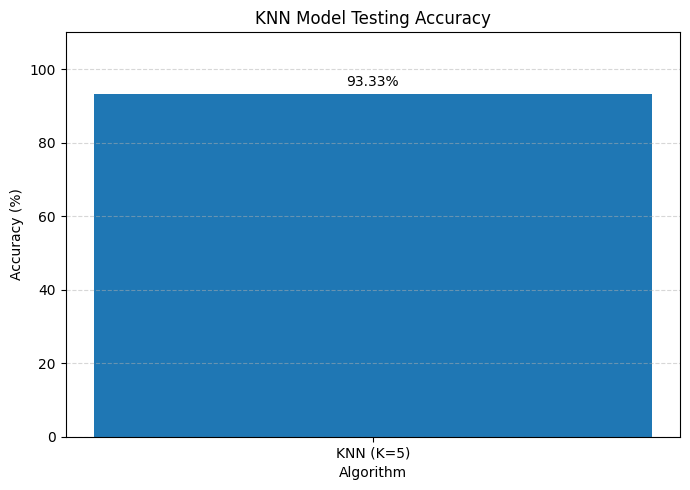


========== NEW SAMPLE PREDICTION ==========
Input Features: [5.1 3.5 1.4 0.2]
Predicted Species: setosa

========== RESULT ==========
KNN algorithm executed successfully.
Number of Neighbours: 5
Testing Accuracy: 93.33 %


In [1]:
# EXPERIMENT 5: K-NEAREST NEIGHBOURS (KNN)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# STEP 1: LOAD TRAINING DATASET
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("========== TRAINING DATASET ==========")
display(df.head(10))

print("\nTotal Samples:", len(df))
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

# STEP 2: SPLIT DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: FEATURE SCALING
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# STEP 4: BUILD KNN MODEL
knn = KNeighborsClassifier(n_neighbors=5)

# STEP 5: TRAIN THE MODEL
knn.fit(X_train_scaled, y_train)

print("\n========== KNN MODEL TRAINED ==========")
print("Algorithm: K-Nearest Neighbours")
print("Number of Neighbours (K):", knn.n_neighbors)

# STEP 6: PREDICT TEST DATA
y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== PREDICTION RESULTS ==========")

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

display(results)

print("Testing Accuracy:", round(accuracy * 100, 2), "%")

# STEP 7: CLASSIFICATION REPORT
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# STEP 8: ACTUAL VS PREDICTED BAR GRAPH
sample_count = min(15, len(y_test))
sample_index = np.arange(sample_count)

plt.figure(figsize=(12, 5))

plt.bar(
    sample_index - 0.2,
    y_test[:sample_count],
    width=0.4,
    label='Actual'
)

plt.bar(
    sample_index + 0.2,
    y_pred[:sample_count],
    width=0.4,
    label='Predicted'
)

plt.title("KNN: Actual vs Predicted Classes")
plt.xlabel("Test Samples")
plt.ylabel("Species Class")

plt.xticks(
    sample_index,
    [f'S{i+1}' for i in sample_index]
)

plt.yticks(
    [0, 1, 2],
    iris.target_names
)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 9: CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 10: ACCURACY BAR GRAPH
plt.figure(figsize=(7, 5))

plt.bar(
    ['KNN (K=5)'],
    [accuracy * 100]
)

plt.title("KNN Model Testing Accuracy")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

plt.text(
    0,
    accuracy * 100 + 2,
    f'{accuracy * 100:.2f}%',
    ha='center'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: TEST A NEW SAMPLE
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

new_sample_scaled = scaler.transform(new_sample)

prediction = knn.predict(new_sample_scaled)

print("\n========== NEW SAMPLE PREDICTION ==========")
print("Input Features:", new_sample[0])
print("Predicted Species:", iris.target_names[prediction[0]])

# STEP 12: FINAL RESULT
print("\n========== RESULT ==========")
print("KNN algorithm executed successfully.")
print("Number of Neighbours:", knn.n_neighbors)
print("Testing Accuracy:", round(accuracy * 100, 2), "%")